<a href="https://colab.research.google.com/github/iam-ramshakhalid/Pothole-Detection/blob/main/F26-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install the roboflow library (-q means "quiet", so less output)
!pip install roboflow -q

# Import the tools we need
from google.colab import userdata   # reads our hidden key from Colab Secrets
from roboflow import Roboflow       # lets us talk to Roboflow

# Read the key from Secrets (it is never written in the notebook)
api_key = userdata.get("ROBOFLOW_API_KEY")

# Connect to Roboflow using the key
rf = Roboflow(api_key=api_key)

# Choose the dataset: workspace name, then project name (from the dataset link)
project = rf.workspace("gerapothole").project("pothole-detection-yolov8")

# Choose version 1 and download it in YOLOv8 format
version = project.version(1)
dataset = version.download("yolov8")

# Show where the files were saved
print("Downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...
Downloaded to: /content/Pothole-detection-YOLOv8-1


In [2]:
import os   # tool for working with folders and files

# The folder where cell 1 saved the dataset
path = dataset.location
print("Dataset folder:", path)

# See what is inside the main folder
print("\nInside the folder:", os.listdir(path))

# Count the images and label files in each part (train, valid, test)
for split in ["train", "valid", "test"]:
    img_folder = os.path.join(path, split, "images")
    lbl_folder = os.path.join(path, split, "labels")
    if os.path.exists(img_folder):
        print(split, "-> images:", len(os.listdir(img_folder)),
              "| labels:", len(os.listdir(lbl_folder)))
    else:
        print(split, "-> folder not found")

# Print data.yaml, the file that lists the class names
print("\n--- data.yaml ---")
print(open(os.path.join(path, "data.yaml")).read())

Dataset folder: /content/Pothole-detection-YOLOv8-1

Inside the folder: ['README.dataset.txt', 'train', 'valid', 'data.yaml', 'README.roboflow.txt', 'test']
train -> images: 1245 | labels: 1245
valid -> images: 120 | labels: 120
test -> images: 62 | labels: 62

--- data.yaml ---
names:
- Potholes
nc: 1
roboflow:
  license: CC BY 4.0
  project: pothole-detection-yolov8
  url: https://universe.roboflow.com/gerapothole/pothole-detection-yolov8/dataset/1
  version: 1
  workspace: gerapothole
test: ../test/images
train: ../train/images
val: ../valid/images



In [3]:
import os

bases = {}   # will hold the "original photo name" of every image, per split

for split in ["train", "valid", "test"]:
    files = os.listdir(os.path.join(path, split, "images"))

    # Roboflow names augmented files like: 22_jpg.rf.<random code>.jpg
    # Everything before ".rf." is the original photo's name
    bases[split] = [f.split(".rf.")[0] for f in files]

    print(split, "example file names:", files[:3])
    print(split, "images:", len(files),
          "| unique original photos:", len(set(bases[split])))
    print()

# Do the same original photo appear in more than one split?
print("Shared between train and valid:", len(set(bases["train"]) & set(bases["valid"])))
print("Shared between train and test :", len(set(bases["train"]) & set(bases["test"])))
print("Shared between valid and test :", len(set(bases["valid"]) & set(bases["test"])))

# Total number of different original photos in the whole dataset
all_unique = set(bases["train"]) | set(bases["valid"]) | set(bases["test"])
print("\nTotal unique original photos:", len(all_unique))

train example file names: ['109_jpg.rf.d6f728cabfde2497202f168657d86623.jpg', '431_jpg.rf.bf09991530a447eab9cc895b40cee05c.jpg', '517_jpg.rf.4fe1fa0d7a99f94759bac7ea2102ccd7.jpg']
train images: 1245 | unique original photos: 425

valid example file names: ['205_jpg.rf.7c02f70327a1a8a5181b0f09189ba6c3.jpg', '503_jpg.rf.37350769c261f565a5586a4787d5791f.jpg', '83_jpg.rf.32f2e7335aa616c6b7fc4aa9a4c09214.jpg']
valid images: 120 | unique original photos: 120

test example file names: ['463_jpg.rf.7158f0539c28f2427c3749050e469ec7.jpg', '401_jpg.rf.e6d4c4f98170e3ffbb0bfda9841a59f4.jpg', '79_jpg.rf.3d21f60cd8dc88795545ed19eb929fca.jpg']
test images: 62 | unique original photos: 62

Shared between train and valid: 0
Shared between train and test : 0
Shared between valid and test : 0

Total unique original photos: 607


In [4]:
import os, shutil

# Make the working folders (we clean these, never the original download)
os.makedirs("work/images", exist_ok=True)
os.makedirs("work/labels", exist_ok=True)

seen = set()            # original photo names we already kept
raw_total = 0           # all images in the download
duplicate_count = 0     # extra copies we skip

for split in ["train", "valid", "test"]:
    img_folder = os.path.join(path, split, "images")
    lbl_folder = os.path.join(path, split, "labels")

    for img_name in sorted(os.listdir(img_folder)):
        raw_total += 1

        # Original photo name = everything before ".rf."
        base = img_name.split(".rf.")[0]

        # If we already kept this photo, skip this extra copy
        if base in seen:
            duplicate_count += 1
            continue
        seen.add(base)

        # Copy the image
        shutil.copy(os.path.join(img_folder, img_name), "work/images/")

        # Copy its label file (same name, but .txt)
        lbl_path = os.path.join(lbl_folder, os.path.splitext(img_name)[0] + ".txt")
        if os.path.exists(lbl_path):
            shutil.copy(lbl_path, "work/labels/")

print("Raw images in download :", raw_total)
print("Duplicates removed     :", duplicate_count)
print("Images kept in work/   :", len(os.listdir("work/images")))
print("Labels kept in work/   :", len(os.listdir("work/labels")))

Raw images in download : 1427
Duplicates removed     : 820
Images kept in work/   : 607
Labels kept in work/   : 607


In [5]:
import os    # for working with files and folders
import cv2   # OpenCV, used here to try opening each image

# Counters: we print these at the end and put them in the report
corrupt_count = 0   # broken images we delete
orphan_count = 0    # images or labels that have no partner file

# ---------- Part A: delete corrupt images ----------
# A corrupt image is one that OpenCV cannot open.
for image_file in os.listdir("work/images"):
    image_path = "work/images/" + image_file

    # Try to open the image. If it is broken, OpenCV gives back None.
    image = cv2.imread(image_path)

    if image is None:
        # Delete the broken image
        os.remove(image_path)

        # Delete its label file too. The label has the same name but ends in .txt
        # (splitext cuts off only the last ending, for example ".jpg")
        name = os.path.splitext(image_file)[0]
        label_path = "work/labels/" + name + ".txt"
        if os.path.exists(label_path):
            os.remove(label_path)

        corrupt_count = corrupt_count + 1

# ---------- Part B: delete orphans ----------
# An orphan is an image with no label file, or a label file with no image.

# B1: images that have no label file
for image_file in os.listdir("work/images"):
    name = os.path.splitext(image_file)[0]
    label_path = "work/labels/" + name + ".txt"

    if not os.path.exists(label_path):
        os.remove("work/images/" + image_file)
        orphan_count = orphan_count + 1

# B2: label files that have no image
# First, make a list of the names of all images that are left
image_names = []
for image_file in os.listdir("work/images"):
    image_names.append(os.path.splitext(image_file)[0])

# Then check every label file against that list
for label_file in os.listdir("work/labels"):
    name = os.path.splitext(label_file)[0]

    if name not in image_names:
        os.remove("work/labels/" + label_file)
        orphan_count = orphan_count + 1

# ---------- Results ----------
print("Corrupt images deleted:", corrupt_count)
print("Orphan files deleted  :", orphan_count)
print("Images left:", len(os.listdir("work/images")))
print("Labels left:", len(os.listdir("work/labels")))

Corrupt images deleted: 0
Orphan files deleted  : 0
Images left: 607
Labels left: 607


In [6]:
import os   # for working with files and folders

# Counters for the report
total_files = 0         # label files we look at
empty_files = 0         # label files with no boxes (images with no pothole)
total_boxes = 0         # all boxes (lines) in all files
bad_format_lines = 0    # lines that do not have 5 proper numbers
wrong_class_lines = 0   # lines where the class number is not 0
out_of_range_lines = 0  # lines where a number is outside 0 to 1

for label_file in os.listdir("work/labels"):
    total_files = total_files + 1

    # Read all lines of this label file
    file = open("work/labels/" + label_file)
    lines = file.readlines()
    file.close()

    # Keep only lines that are not blank
    boxes = []
    for line in lines:
        if line.strip() != "":
            boxes.append(line)

    # A file with no boxes means the image has no pothole marked
    if len(boxes) == 0:
        empty_files = empty_files + 1

    # Check every box in this file
    for line in boxes:
        total_boxes = total_boxes + 1
        parts = line.split()   # split the line into its values

        # There must be exactly 5 values
        if len(parts) != 5:
            bad_format_lines = bad_format_lines + 1
            continue   # skip to the next line

        # Turn the text values into numbers
        try:
            class_id = int(parts[0])
            x = float(parts[1])
            y = float(parts[2])
            w = float(parts[3])
            h = float(parts[4])
        except ValueError:
            # One of the values is not a number
            bad_format_lines = bad_format_lines + 1
            continue

        # The class number must be 0 (pothole)
        if class_id != 0:
            wrong_class_lines = wrong_class_lines + 1

        # All box numbers must be between 0 and 1 (width and height above 0)
        if x < 0 or x > 1 or y < 0 or y > 1 or w <= 0 or w > 1 or h <= 0 or h > 1:
            out_of_range_lines = out_of_range_lines + 1

print("Label files checked      :", total_files)
print("Files with no boxes      :", empty_files)
print("Total boxes              :", total_boxes)
print("Lines with bad format    :", bad_format_lines)
print("Lines with wrong class   :", wrong_class_lines)
print("Lines out of 0-1 range   :", out_of_range_lines)

Label files checked      : 607
Files with no boxes      : 0
Total boxes              : 2425
Lines with bad format    : 0
Lines with wrong class   : 0
Lines out of 0-1 range   : 0


In [7]:
import os
import cv2

widths = []              # width of every image
heights = []             # height of every image
size_counts = {}         # how many images have each size, e.g. "640x640": 607
not_color_count = 0      # images that do not have 3 color channels

for image_file in os.listdir("work/images"):
    image = cv2.imread("work/images/" + image_file)

    # image.shape gives (height, width, number of color channels)
    height, width, channels = image.shape

    widths.append(width)
    heights.append(height)

    # Count how many images have this exact size
    size_text = str(width) + "x" + str(height)
    if size_text in size_counts:
        size_counts[size_text] = size_counts[size_text] + 1
    else:
        size_counts[size_text] = 1

    # A normal color image has 3 channels
    if channels != 3:
        not_color_count = not_color_count + 1

print("Images checked:", len(widths))
print("Smallest width :", min(widths), "| Largest width :", max(widths))
print("Smallest height:", min(heights), "| Largest height:", max(heights))
print("Average width  :", sum(widths) / len(widths))
print("Average height :", sum(heights) / len(heights))
print("Images without 3 color channels:", not_color_count)

# Show the different sizes (first 10 only, in case there are many)
print("\nNumber of different sizes:", len(size_counts))
shown = 0
for size_text in size_counts:
    if shown < 10:
        print(size_text, "->", size_counts[size_text], "images")
        shown = shown + 1

Images checked: 607
Smallest width : 640 | Largest width : 640
Smallest height: 640 | Largest height: 640
Average width  : 640.0
Average height : 640.0
Images without 3 color channels: 0

Number of different sizes: 1
640x640 -> 607 images


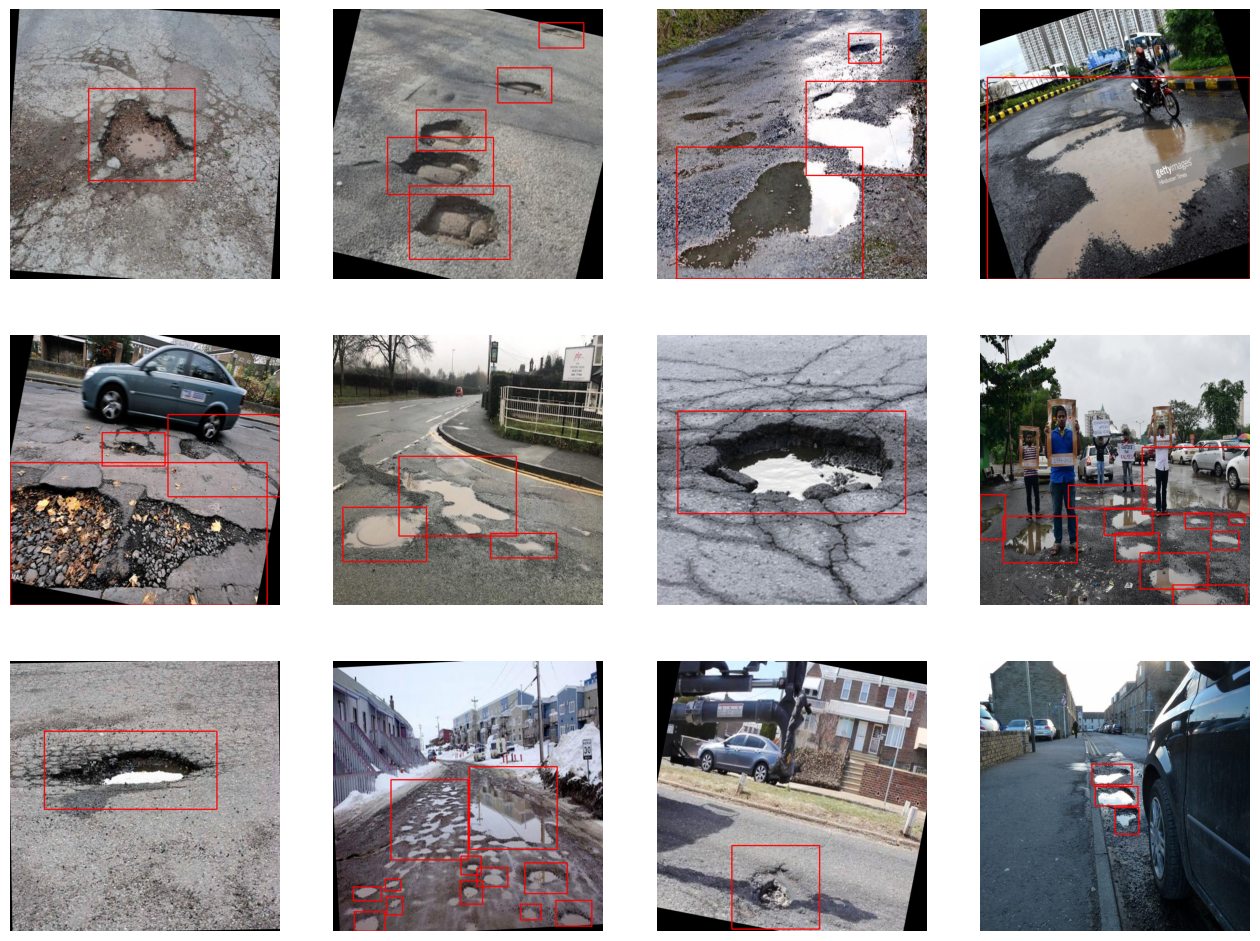

In [8]:
import os
import random
import cv2
import matplotlib.pyplot as plt

# Pick 12 random images from the work folder
image_files = os.listdir("work/images")
chosen = random.sample(image_files, 12)

plt.figure(figsize=(16, 12))   # size of the whole picture
position = 1                   # which square of the 3x4 grid we are filling

for image_file in chosen:
    # Open the image (OpenCV loads colors as BGR, so convert to RGB for display)
    image = cv2.imread("work/images/" + image_file)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width, channels = image.shape

    # Open the label file that belongs to this image
    name = os.path.splitext(image_file)[0]
    label_file = open("work/labels/" + name + ".txt")

    for line in label_file.readlines():
        parts = line.split()
        if len(parts) == 5:
            # Read the box numbers (these are fractions between 0 and 1)
            x_center = float(parts[1])
            y_center = float(parts[2])
            box_width = float(parts[3])
            box_height = float(parts[4])

            # Convert the fractions to pixel positions of the box corners
            x1 = int((x_center - box_width / 2) * width)
            y1 = int((y_center - box_height / 2) * height)
            x2 = int((x_center + box_width / 2) * width)
            y2 = int((y_center + box_height / 2) * height)

            # Draw a red rectangle on the image
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

    label_file.close()

    # Put this image in the grid
    plt.subplot(3, 4, position)
    plt.imshow(image)
    plt.axis("off")
    position = position + 1

plt.show()

In [9]:
import os
import random
import shutil

def split_dataset(train_ratio=0.7, val_ratio=0.2):
    """Shuffle the images in work/ and copy them into train, val and test folders.
    Returns the number of images in each split."""

    # Start fresh: delete the old output folder if it exists
    if os.path.exists("our_clean_dataset"):
        shutil.rmtree("our_clean_dataset")

    # Shuffle the image names (the seed makes the split repeatable)
    random.seed(42)
    image_files = os.listdir("work/images")
    random.shuffle(image_files)

    # Work out where to cut the shuffled list
    total = len(image_files)
    train_end = int(total * train_ratio)
    val_end = int(total * (train_ratio + val_ratio))

    splits = {
        "train": image_files[:train_end],
        "val": image_files[train_end:val_end],
        "test": image_files[val_end:],
    }

    counts = {}
    for split_name in splits:
        os.makedirs("our_clean_dataset/images/" + split_name)
        os.makedirs("our_clean_dataset/labels/" + split_name)

        for image_file in splits[split_name]:
            # The label has the same name as the image, but ends in .txt
            name = os.path.splitext(image_file)[0]
            shutil.copy("work/images/" + image_file,
                        "our_clean_dataset/images/" + split_name + "/" + image_file)
            shutil.copy("work/labels/" + name + ".txt",
                        "our_clean_dataset/labels/" + split_name + "/" + name + ".txt")

        counts[split_name] = len(splits[split_name])

    return counts


# Run the split and print the result
split_counts = split_dataset()
print(split_counts)

{'train': 424, 'val': 122, 'test': 61}


In [10]:
# The lines of text that go inside data.yaml
# This file tells the AI where the train, val and test folders are
# nc = number of classes (we only have one: Potholes)
yaml_lines = [
    "path: /content/our_clean_dataset",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "nc: 1",
    "names:",
    "  0: Potholes",
]

# Write the lines into data.yaml, one line at a time
file = open("our_clean_dataset/data.yaml", "w")
for line in yaml_lines:
    file.write(line + "\n")
file.close()

# Read the file back and print it, to check it was written correctly
file = open("our_clean_dataset/data.yaml")
for line in file.readlines():
    print(line.strip())
file.close()

path: /content/our_clean_dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
0: Potholes


Total boxes: 2425
Boxes per class: Potholes -> 2425
Boxes per split:
split
train    1673
val       553
test      199
Name: count, dtype: int64


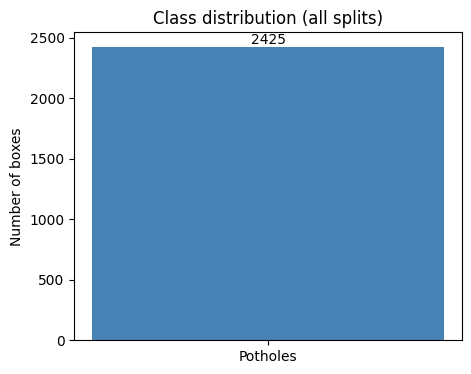

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Class names, in the same order as the class numbers in data.yaml (0 = Potholes)
class_names = ["Potholes"]

# We collect one row per box here, then turn the list into a table
rows = []

# Go through every label file in the final dataset
for split in ["train", "val", "test"]:
    label_folder = "our_clean_dataset/labels/" + split

    for label_file in os.listdir(label_folder):
        file = open(label_folder + "/" + label_file)
        lines = file.readlines()
        file.close()

        # Every line with 5 values is one box
        for line in lines:
            parts = line.split()
            if len(parts) == 5:
                rows.append({
                    "split": split,
                    "class_id": int(parts[0]),
                    "width": float(parts[3]),    # box width as a fraction of the image
                    "height": float(parts[4]),   # box height as a fraction of the image
                })

# Turn the list into a table (one row per box)
boxes = pd.DataFrame(rows)

# Box area as a fraction of the whole image (we use this in the next step)
boxes["area"] = boxes["width"] * boxes["height"]

# Count how many boxes each class has, and how many boxes each split has
class_counts = boxes["class_id"].value_counts().sort_index()
split_counts = boxes["split"].value_counts()

# Print the numbers so we can use them in the report
print("Total boxes:", len(boxes))
print("Boxes per class:", class_names[0], "->", class_counts[0])
print("Boxes per split:")
print(split_counts)

# Draw the bar chart (Graph 1)
plt.figure(figsize=(5, 4))
plt.bar(class_names, class_counts, color="steelblue")
plt.title("Class distribution (all splits)")
plt.ylabel("Number of boxes")

# Write the count on top of the bar
plt.text(0, class_counts[0], str(class_counts[0]), ha="center", va="bottom")

# Save the picture for the report, then show it
plt.savefig("graph1_classes.png", dpi=150, bbox_inches="tight")
plt.show()

Small boxes  (<1% of image)  : 506
Medium boxes (1% to 10%)     : 1295
Large boxes  (>10% of image) : 624
Average boxes per image      : 4.0
Average box area             : 10.09 % of the image
Median box area              : 3.02 % of the image
Largest box area             : 100.0 % of the image


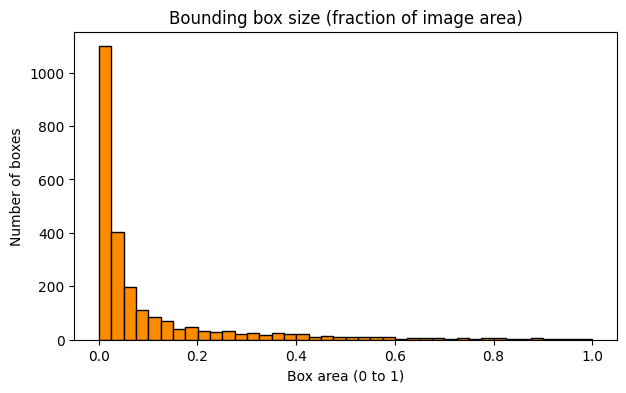

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Box area is a fraction of the whole image (0 to 1)
# We call a box small, medium or large depending on how much of the image it covers
small_boxes = boxes[boxes["area"] < 0.01]                                # less than 1% of the image
medium_boxes = boxes[(boxes["area"] >= 0.01) & (boxes["area"] < 0.10)]   # 1% to 10%
large_boxes = boxes[boxes["area"] >= 0.10]                               # 10% or more

# Count the images in the final dataset (needed for the average boxes per image)
total_images = 0
for split in ["train", "val", "test"]:
    total_images = total_images + len(os.listdir("our_clean_dataset/images/" + split))

# Print the numbers so we can use them in the report
print("Small boxes  (<1% of image)  :", len(small_boxes))
print("Medium boxes (1% to 10%)     :", len(medium_boxes))
print("Large boxes  (>10% of image) :", len(large_boxes))
print("Average boxes per image      :", round(len(boxes) / total_images, 2))
print("Average box area             :", round(boxes["area"].mean() * 100, 2), "% of the image")
print("Median box area              :", round(np.median(boxes["area"]) * 100, 2), "% of the image")
print("Largest box area             :", round(boxes["area"].max() * 100, 2), "% of the image")

# Draw the histogram (Graph 3)
plt.figure(figsize=(7, 4))
plt.hist(boxes["area"], bins=40, color="darkorange", edgecolor="black")
plt.title("Bounding box size (fraction of image area)")
plt.xlabel("Box area (0 to 1)")
plt.ylabel("Number of boxes")

# Save the picture for the report, then show it
plt.savefig("graph3_boxsize.png", dpi=150, bbox_inches="tight")
plt.show()

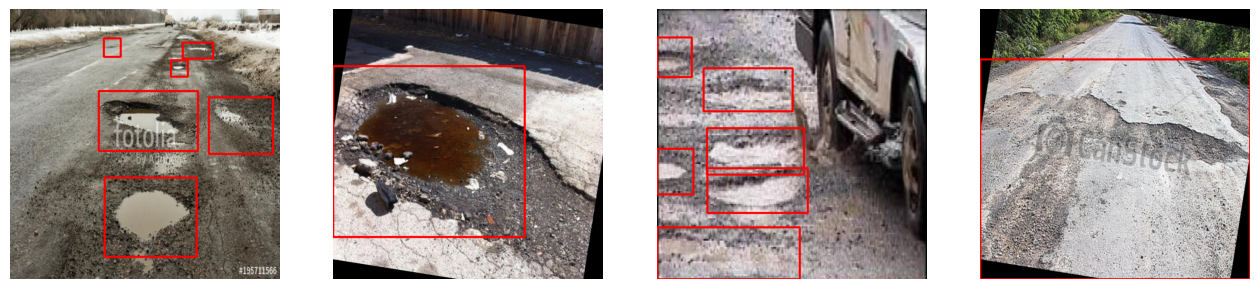

In [13]:
import os
import random
import cv2
import matplotlib.pyplot as plt

# Pick 4 random images from the final train folder
# (the seed makes the same 4 images appear every time we run the cell)
random.seed(7)
image_files = os.listdir("our_clean_dataset/images/train")
chosen = random.sample(image_files, 4)

plt.figure(figsize=(16, 4))   # size of the whole picture
position = 1                  # which square of the 1x4 grid we are filling

for image_file in chosen:
    # Open the image (OpenCV loads colors as BGR, so convert to RGB for display)
    image = cv2.imread("our_clean_dataset/images/train/" + image_file)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width, channels = image.shape

    # Open the label file that belongs to this image
    name = os.path.splitext(image_file)[0]
    label_file = open("our_clean_dataset/labels/train/" + name + ".txt")

    for line in label_file.readlines():
        parts = line.split()
        if len(parts) == 5:
            # Read the box numbers (these are fractions between 0 and 1)
            x_center = float(parts[1])
            y_center = float(parts[2])
            box_width = float(parts[3])
            box_height = float(parts[4])

            # Convert the fractions to pixel positions of the box corners
            x1 = int((x_center - box_width / 2) * width)
            y1 = int((y_center - box_height / 2) * height)
            x2 = int((x_center + box_width / 2) * width)
            y2 = int((y_center + box_height / 2) * height)

            # Draw a red rectangle on the image
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 3)

    label_file.close()

    # Put this image in the grid
    plt.subplot(1, 4, position)
    plt.imshow(image)
    plt.axis("off")
    position = position + 1

# Save the picture for the report, then show it
plt.savefig("graph2_samples.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
import os
import pandas as pd

# Tiny images: every image is already 640x640, so none were below a cutoff
tiny_count = 0

# ---------- Cleaning counters (for Section 3 of the report) ----------
print("---- CLEANING COUNTERS ----")
print("Raw images in download   :", raw_total)
print("Duplicate copies removed :", duplicate_count)
print("Corrupt images deleted   :", corrupt_count)
print("Orphan files deleted     :", orphan_count)
print("Tiny images deleted      :", tiny_count)
print("Label lines, bad format  :", bad_format_lines)
print("Label lines, wrong class :", wrong_class_lines)
print("Label lines, out of range:", out_of_range_lines)
print("Empty label files        :", empty_files)
print("Image size               : 640x640, 3 color channels (RGB)")

# ---------- Final split table (for Section 5 of the report) ----------
rows = []
for split in ["train", "val", "test"]:
    image_count = len(os.listdir("our_clean_dataset/images/" + split))
    label_count = len(os.listdir("our_clean_dataset/labels/" + split))
    box_count = len(boxes[boxes["split"] == split])
    rows.append([split, image_count, label_count, box_count])

summary = pd.DataFrame(rows, columns=["Split", "Images", "Label files", "Boxes"])

# Add a total row at the bottom
total_images = summary["Images"].sum()
summary.loc[3] = ["total", total_images,
                  summary["Label files"].sum(), summary["Boxes"].sum()]

# Add the share of images in each split, as a percentage
summary["Images %"] = (summary["Images"] / total_images * 100).round(1)

print("\n---- FINAL DATASET SUMMARY ----")
print(summary)

# Every image must have exactly one label file
if summary["Images"].sum() == summary["Label files"].sum():
    print("\nCheck passed: every image has a label file")
else:
    print("\nWARNING: image and label counts do not match")

---- CLEANING COUNTERS ----
Raw images in download   : 1427
Duplicate copies removed : 820
Corrupt images deleted   : 0
Orphan files deleted     : 0
Tiny images deleted      : 0
Label lines, bad format  : 0
Label lines, wrong class : 0
Label lines, out of range: 0
Empty label files        : 0
Image size               : 640x640, 3 color channels (RGB)

---- FINAL DATASET SUMMARY ----
   Split  Images  Label files  Boxes  Images %
0  train     424          424   1673      69.9
1    val     122          122    553      20.1
2   test      61           61    199      10.0
3  total     607          607   2425     100.0

Check passed: every image has a label file


In [15]:
import os
import shutil
from google.colab import drive

# Connect Google Drive to this notebook (a pop-up will ask for permission)
drive.mount("/content/drive")

# The folder in Google Drive where we keep our backup
backup_folder = "/content/drive/MyDrive/F26-1"
os.makedirs(backup_folder, exist_ok=True)

# Copy the final dataset (delete the old backup first, so the copy is clean)
if os.path.exists(backup_folder + "/our_clean_dataset"):
    shutil.rmtree(backup_folder + "/our_clean_dataset")
shutil.copytree("our_clean_dataset", backup_folder + "/our_clean_dataset")

# Copy the three graphs for the report
graph_files = ["graph1_classes.png", "graph2_samples.png", "graph3_boxsize.png"]
for graph_file in graph_files:
    if os.path.exists(graph_file):
        shutil.copy(graph_file, backup_folder + "/" + graph_file)
    else:
        print("WARNING: graph not found, run its cell first:", graph_file)

# Check what was saved
print("Saved in Google Drive:", os.listdir(backup_folder))
print("Images in backup (train, val, test):",
      len(os.listdir(backup_folder + "/our_clean_dataset/images/train")),
      len(os.listdir(backup_folder + "/our_clean_dataset/images/val")),
      len(os.listdir(backup_folder + "/our_clean_dataset/images/test")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved in Google Drive: ['graph1_classes.png', 'graph2_samples.png', 'graph3_boxsize.png', 'our_clean_dataset']
Images in backup (train, val, test): 424 122 61
